# FinGraph AI — 03 | Dijagnostika prije optimizacije (četvrti eksperiment)

**Namjena:** provjeriti uzroke slabije generalizacije XGBoost, GraphSAGE i MLP modela, bez podešavanja hiperparametara. Notebook čita postojeće predikcije i, po izboru, ponavlja treniranje **početnih** konfiguracija na tri ranije hronološke podjele. Analizira promjene klasa/karakteristika, kvalitet rangiranja i pragova, kalibraciju, grafovska susjedstva i 2–3 visokorizična podgrafa.

**Sigurnost protokola:** testni koraci 42–49 već su pregledani; njihove analize su **retrospektivne/eksploratorne**, ne služe za izbor konfiguracija ni praga. Novi hronološki pokusi koriste razvojne korake ≤41. `unknown = -1` nije negativna klasa. Nijedan izlaz ne prepisuje prethodne eksperimente.

**Izlazi:** isključivo u `outputs/phase04_diagnostics/`. Fajlovi počinju prefiksom `phase04_`. Notebook se zove `03_phase04_diagnostics.ipynb`, jer postojeći redoslijed notebookova završava s `02_...`.

In [1]:
from pathlib import Path
import os, sys

try:
    if Path('/content').exists():
        from google.colab import drive
        drive.mount('/content/drive')
except Exception as exc:
    print('Drive mount preskočen:', exc)

PROJECT_DIR = Path('/content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter')
if not PROJECT_DIR.is_dir():
    PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'src/fingraph/data.py').exists():
    raise FileNotFoundError('Postavi PROJECT_DIR na folder projekta iz verzije 3.')
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR / 'src'))
print('Projekt:', PROJECT_DIR)

Mounted at /content/drive
Projekt: /content/drive/MyDrive/fingraph-ai/FinGraph_AI_MPVI_Starter


In [2]:
# U Colabu jednom instalirati projekt i zavisnosti. PyG samo za opciono GraphSAGE ponovno treniranje.
%pip install -q -e . networkx scipy seaborn

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for fingraph-ai-mpvi (pyproject.toml) ... done


In [3]:
import json, random, warnings, math, copy
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import networkx as nx
from scipy.stats import wasserstein_distance, ks_2samp
from sklearn.metrics import (average_precision_score, roc_auc_score, confusion_matrix,
    precision_score, recall_score, f1_score, fbeta_score, brier_score_loss,
    precision_recall_curve, roc_curve)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from fingraph.data import load_elliptic
from fingraph.splits import make_time_splits, edges_observed_until
from fingraph.temporal import load_and_check_test_predictions, evaluate_per_time, joined_predictions

SEED = 42
np.random.seed(SEED)
OUT = Path('outputs/phase04_diagnostics')
TABLES, FIGS, RUNS, SUBGRAPHS = (OUT / p for p in ('tables','figures','rolling_runs','subgraphs'))
for p in (TABLES,FIGS,RUNS,SUBGRAPHS): p.mkdir(parents=True,exist_ok=True)

def save_table(df, name, index=False):
    p = TABLES / f'phase04_{name}.csv'; df.to_csv(p,index=index); print('Sačuvano:',p); return p

def save_fig(name):
    p=FIGS/f'phase04_{name}.png'; plt.tight_layout(); plt.savefig(p,dpi=175,bbox_inches='tight'); plt.show(); print('Sačuvano:',p)

def dump_json(obj, name):
    p=OUT/f'phase04_{name}.json'; p.write_text(json.dumps(obj,indent=2,ensure_ascii=False,default=str),encoding='utf8'); return p

print('Svi izlazi idu u',OUT)

Svi izlazi idu u outputs/phase04_diagnostics


## 1. Učitavanje i audit (bez treniranja)
Provjera broja čvorova, vremena, oznaka, rubova i oznaka u svakom prozoru. Podaci se učitavaju istim `load_elliptic()` loaderom kao u prethodnim eksperimentima.

Čvorovi 203769 veze 234355 karakteristike 182
Sačuvano: outputs/phase04_diagnostics/tables/phase04_label_distribution_by_time.csv
Sačuvano: outputs/phase04_diagnostics/tables/phase04_original_split_counts.csv


,partition,n,positives,prevalence
0,train,29894,3462,0.115809
1,validation,7829,675,0.086218
2,test,8841,408,0.046149


Sačuvano: outputs/phase04_diagnostics/tables/phase04_edge_time_checks.csv


,edges,same_step,cross_step,self_loops
0,234355,234355,0,0


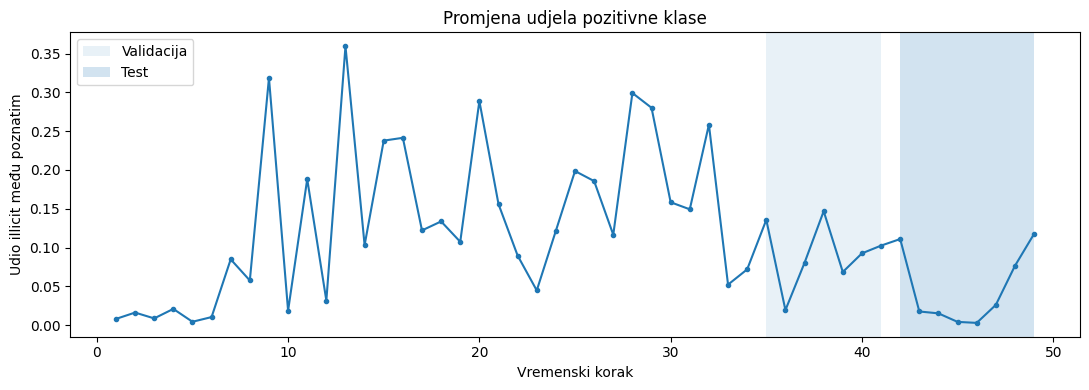

Sačuvano: outputs/phase04_diagnostics/figures/phase04_positive_rate_by_time.png


In [4]:
graph=load_elliptic('data/raw'); splits=make_time_splits(graph)
print('Čvorovi',graph.num_nodes,'veze',graph.num_edges,'karakteristike',graph.features.shape[1])
assert len(graph.feature_names)==graph.features.shape[1]
src,dst=graph.edge_index
assert np.all((src>=0)&(src<graph.num_nodes)&(dst>=0)&(dst<graph.num_nodes))
by_time=[]
for t in sorted(np.unique(graph.times)):
    m=graph.times==t; lab=graph.labels[m]; known=lab>=0
    by_time.append(dict(time_step=int(t),n_all=int(m.sum()),n_known=int(known.sum()),
       n_illicit=int((lab==1).sum()),n_licit=int((lab==0).sum()),n_unknown=int((lab==-1).sum()),
       illicit_rate_known=float((lab==1).sum()/known.sum()) if known.sum() else np.nan,
       unknown_fraction=float((lab==-1).mean())))
time_df=pd.DataFrame(by_time); save_table(time_df,'label_distribution_by_time')
summary=pd.DataFrame([dict(partition=n,n=int(m.sum()),positives=int((graph.labels[m]==1).sum()),
   prevalence=float((graph.labels[m]==1).mean())) for n,m in [('train',splits.train),('validation',splits.valid),('test',splits.test)]])
save_table(summary,'original_split_counts'); display(summary)
edge_stats=pd.DataFrame([{'edges':len(src),'same_step':int((graph.times[src]==graph.times[dst]).sum()),
    'cross_step':int((graph.times[src]!=graph.times[dst]).sum()),
    'self_loops':int((src==dst).sum())}]); save_table(edge_stats,'edge_time_checks');display(edge_stats)
fig,ax=plt.subplots(figsize=(11,4)); ax.plot(time_df.time_step,time_df.illicit_rate_known,marker='o',markersize=3)
ax.axvspan(35,41,alpha=.1,label='Validacija');ax.axvspan(42,49,alpha=.2,label='Test');ax.set(xlabel='Vremenski korak',ylabel='Udio illicit među poznatim',title='Promjena udjela pozitivne klase');ax.legend(); save_fig('positive_rate_by_time')

## 2. Postojeće testne predikcije: usklađivanje, vremenske metrike, koncentracija TP
Učitavaju se originalni `outputs/xgboost`, `outputs/graphsage` i `outputs/mlp_v1`; prethodne datoteke ostaju nepromijenjene.

Poravnato transakcija: 8841 | pragovi: {'XGBoost': 0.7699999999999999, 'GraphSAGE': 0.8799999999999999, 'MLP': 0.9099999999999999}
Sačuvano: outputs/phase04_diagnostics/tables/phase04_original_models_temporal_metrics_with_ap_lift.csv
Sačuvano: outputs/phase04_diagnostics/tables/phase04_true_positive_concentration.csv


,model,TP_step42,TP_steps43_49,positives_step42,positives_steps43_49,recall_steps43_49
0,XGBoost,192,3,239,169,0.017751
1,GraphSAGE,145,2,239,169,0.011834
2,MLP,185,7,239,169,0.041420


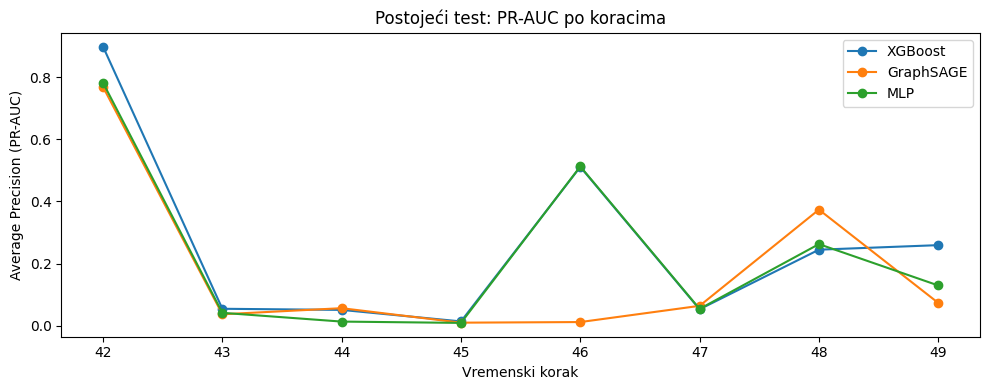

Sačuvano: outputs/phase04_diagnostics/figures/phase04_original_pr_auc_by_time.png


In [6]:
paths={'XGBoost':Path('outputs/xgboost'),'GraphSAGE':Path('outputs/graphsage'),'MLP':Path('outputs/mlp_v1')}
preds={}; old_metrics={}; thresholds={}
for name,folder in paths.items():
    old_metrics[name]=json.loads((folder/'metrics.json').read_text(encoding='utf8'))
    preds[name]=load_and_check_test_predictions(folder/'test_predictions.csv',graph,splits)
    thresholds[name]=float(old_metrics[name]['test']['threshold'])
    saved_ap=float(old_metrics[name]['test']['pr_auc'])
    computed_ap=average_precision_score(preds[name].label,preds[name].probability_illicit)
    assert np.isclose(saved_ap,computed_ap,atol=1e-5),f'{name}: neusklađene metrike'
aligned=joined_predictions(preds)
assert len(aligned)==int(splits.test.sum())
print('Poravnato transakcija:',len(aligned),'| pragovi:',thresholds)
all_temporal=pd.concat([evaluate_per_time(df,thresholds[n]).assign(model=n) for n,df in preds.items()],ignore_index=True)
all_temporal['ap_lift']=all_temporal.pr_auc/all_temporal.positive_rate.replace(0,np.nan)
save_table(all_temporal,'original_models_temporal_metrics_with_ap_lift')
concentration=[]
for name,df in preds.items():
    y=df.label.to_numpy(); p=df.probability_illicit.to_numpy(); positive=p>=thresholds[name]
    a=(df.time_step.to_numpy()==42); b=~a
    concentration.append(dict(model=name,TP_step42=int((positive&a&(y==1)).sum()),
       TP_steps43_49=int((positive&b&(y==1)).sum()),
       positives_step42=int((a&(y==1)).sum()),positives_steps43_49=int((b&(y==1)).sum()),
       recall_steps43_49=float(((positive&b&(y==1)).sum())/(b&(y==1)).sum())))
concent=pd.DataFrame(concentration);save_table(concent,'true_positive_concentration');display(concent)
fig,ax=plt.subplots(figsize=(10,4))
for name in preds:
    sub=all_temporal[all_temporal.model==name];ax.plot(sub.time_step,sub.pr_auc,marker='o',label=name)
ax.set(xlabel='Vremenski korak',ylabel='Average Precision (PR-AUC)',title='Postojeći test: PR-AUC po koracima');ax.legend();save_fig('original_pr_auc_by_time')

## 3. Skorovi i rangiranje: korak 42 naspram 43–49
**Dijagnostika samo na već pregledanom testu**: raspodjele skorova po klasi, kvalitet rangiranja, AP i Precision@K / Recall@K. Ne birati novi konačni prag na osnovu ovih podataka.

Sačuvano: outputs/phase04_diagnostics/tables/phase04_score_quantiles_by_period_and_class.csv
Sačuvano: outputs/phase04_diagnostics/tables/phase04_ranking_topk_by_period.csv


,model,period,label,n,p10,median,p90,fraction_above_fixed_threshold
0,XGBoost,step42,0,1915,0.0000,0.0004,0.0358,0.0042
1,XGBoost,step42,1,239,0.0161,0.9982,0.9996,0.8033
2,XGBoost,steps43_49,0,6518,0.0000,0.0009,0.0681,0.0043
3,XGBoost,steps43_49,1,169,0.0014,0.0077,0.1678,0.0178
4,XGBoost,full_test,0,8433,0.0000,0.0007,0.0604,0.0043
5,XGBoost,full_test,1,408,0.0025,0.3706,0.9994,0.4779
6,GraphSAGE,step42,0,1915,0.0000,0.0203,0.6027,0.0204
7,GraphSAGE,step42,1,239,0.3288,0.9190,0.9892,0.6067
8,GraphSAGE,steps43_49,0,6518,0.0000,0.0334,0.7093,0.0222
9,GraphSAGE,steps43_49,1,169,0.0000,0.2491,0.7017,0.0118


,model,period,k,hit,precision_at_k,recall_at_k,ap,prevalence
0,XGBoost,step42,25,25,1.000,0.1046,0.8976,0.1110
1,XGBoost,step42,50,50,1.000,0.2092,0.8976,0.1110
2,XGBoost,step42,100,100,1.000,0.4184,0.8976,0.1110
3,XGBoost,step42,200,192,0.960,0.8033,0.8976,0.1110
4,XGBoost,steps43_49,25,3,0.120,0.0178,0.0524,0.0253
5,XGBoost,steps43_49,50,4,0.080,0.0237,0.0524,0.0253
6,XGBoost,steps43_49,100,6,0.060,0.0355,0.0524,0.0253
7,XGBoost,steps43_49,200,10,0.050,0.0592,0.0524,0.0253
8,XGBoost,full_test,25,25,1.000,0.0613,0.5675,0.0461
9,XGBoost,full_test,50,50,1.000,0.1225,0.5675,0.0461


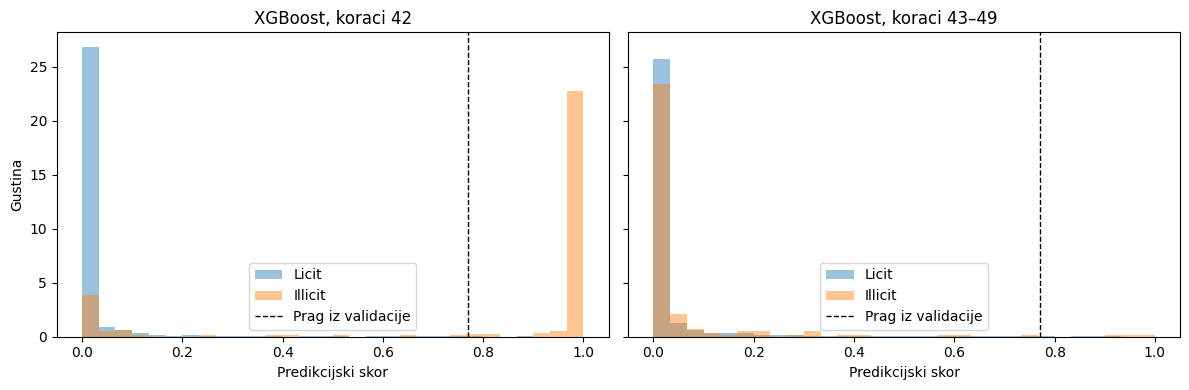

Sačuvano: outputs/phase04_diagnostics/figures/phase04_score_hist_xgboost.png


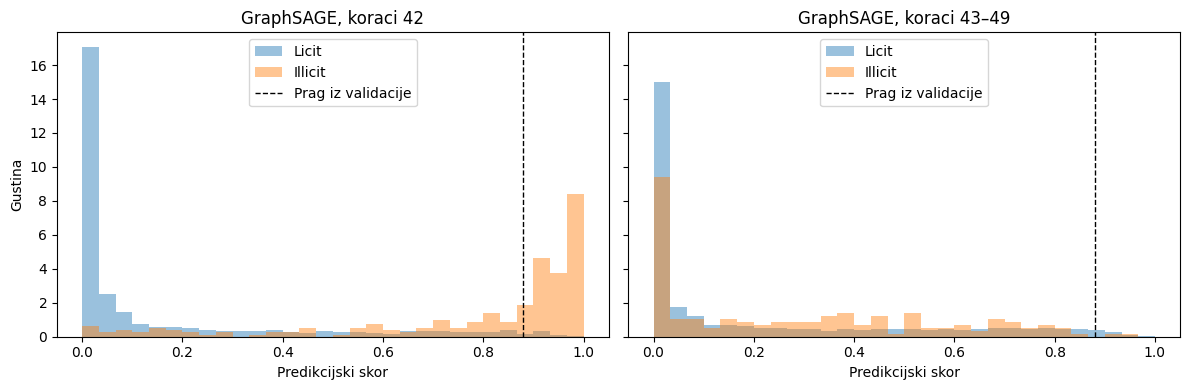

Sačuvano: outputs/phase04_diagnostics/figures/phase04_score_hist_graphsage.png


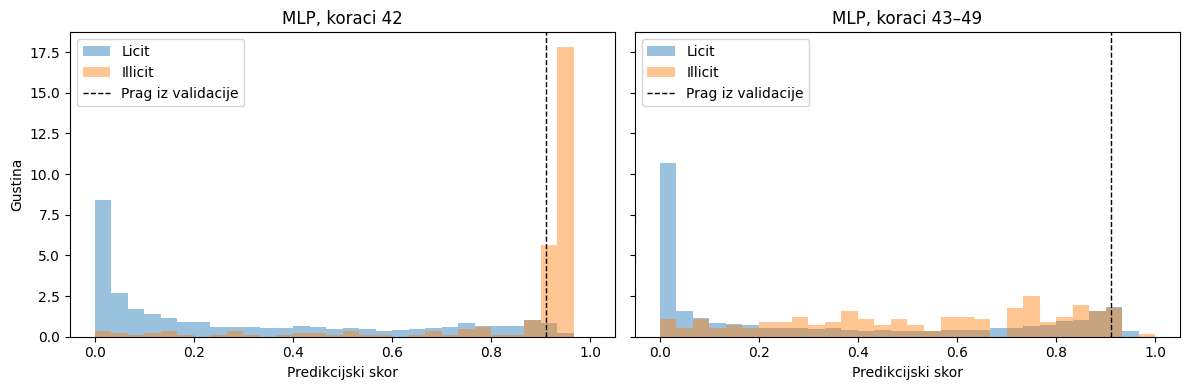

Sačuvano: outputs/phase04_diagnostics/figures/phase04_score_hist_mlp.png


In [ ]:
def topk_metrics(y,p,k):
    k=min(int(k),len(y));order=np.argsort(-p,kind='stable')[:k]; hits=int(y[order].sum())
    return dict(k=k,hit=hits,precision_at_k=hits/k,recall_at_k=hits/max(int(y.sum()),1))
sc_rows=[];rank_rows=[]
for name,df in preds.items():
    for period,cut in [('step42',df.time_step==42),('steps43_49',df.time_step>=43),('full_test',pd.Series(True,index=df.index))]:
        d=df.loc[cut]; y=d.label.to_numpy();p=d.probability_illicit.to_numpy()
        for lab in (0,1):
            v=p[y==lab]
            sc_rows.append(dict(model=name,period=period,label=lab,n=len(v),
              p10=float(np.quantile(v,.1)),median=float(np.median(v)),p90=float(np.quantile(v,.9)),
              fraction_above_fixed_threshold=float(np.mean(v>=thresholds[name]))))
        for k in (25,50,100,200):rank_rows.append(dict(model=name,period=period,**topk_metrics(y,p,k),
              ap=float(average_precision_score(y,p)),prevalence=float(y.mean())))
score_table=pd.DataFrame(sc_rows);rank_table=pd.DataFrame(rank_rows)
save_table(score_table,'score_quantiles_by_period_and_class')
save_table(rank_table,'ranking_topk_by_period')
display(score_table.round(4));display(rank_table.round(4))
for name,df in preds.items():
    fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
    for ax,(period,m) in zip(axes,[('42',df.time_step==42),('43–49',df.time_step>=43)]):
        for lab,label in ((0,'Licit'),(1,'Illicit')):
            p=df.loc[m&(df.label==lab),'probability_illicit'].to_numpy()
            ax.hist(p,bins=np.linspace(0,1,31),density=True,alpha=.45,label=label)
        ax.axvline(thresholds[name],ls='--',c='black',lw=1,label='Prag iz validacije')
        ax.set(xlabel='Predikcijski skor',title=f'{name}, koraci {period}');ax.legend()
    axes[0].set_ylabel('Gustina');save_fig(f'score_hist_{name.lower()}')

## 4. Krivulje pri različitim pragovima (retrospektivna dijagnostika)
Cilj je otkriti da li se pozitivni primjeri nalaze neposredno ispod postojećeg praga. **Pragovi se ovdje ne optimizuju**. Pored PR-krivulja izračunava se presjek pri unaprijed fiksiranim pragovima, a rezultati su isključivo eksploratorni.

Sačuvano: outputs/phase04_diagnostics/tables/phase04_fixed_threshold_sensitivity_DESCRIPTIVE_ONLY.csv


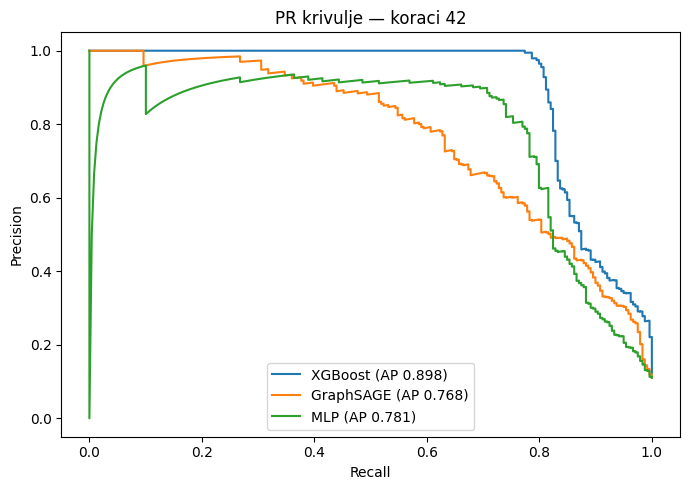

Sačuvano: outputs/phase04_diagnostics/figures/phase04_pr_curve_42_DESCRIPTIVE_ONLY.png


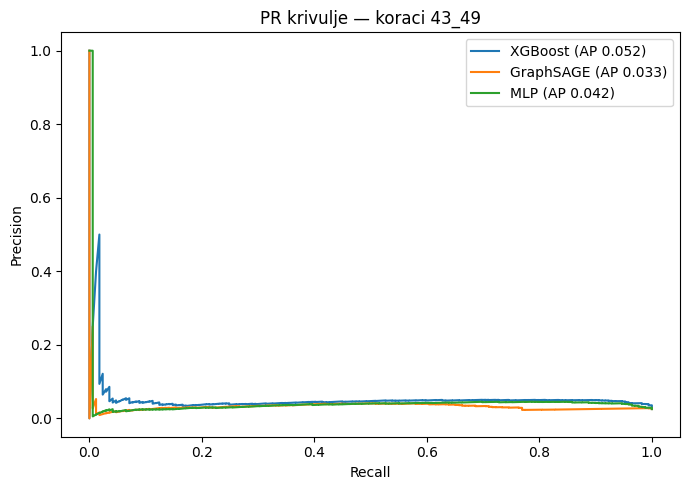

Sačuvano: outputs/phase04_diagnostics/figures/phase04_pr_curve_43_49_DESCRIPTIVE_ONLY.png


In [ ]:
threshold_grid=[0.1,0.3,0.5,0.7,0.9]
threshold_rows=[]
for name,df in preds.items():
    for period,m in [('42',df.time_step==42),('43_49',df.time_step>=43),('all',pd.Series(True,index=df.index))]:
        y=df.loc[m,'label'].to_numpy(); p=df.loc[m,'probability_illicit'].to_numpy()
        for th in sorted(set(threshold_grid+[thresholds[name]])):
            z=p>=th;tn,fp,fn,tp=confusion_matrix(y,z,labels=[0,1]).ravel()
            threshold_rows.append(dict(model=name,period=period,threshold=th,tp=int(tp),fp=int(fp),tn=int(tn),fn=int(fn),
                precision=precision_score(y,z,zero_division=0),recall=recall_score(y,z,zero_division=0),
                f1=f1_score(y,z,zero_division=0),f2=fbeta_score(y,z,beta=2,zero_division=0)))
threshold_tbl=pd.DataFrame(threshold_rows);save_table(threshold_tbl,'fixed_threshold_sensitivity_DESCRIPTIVE_ONLY')
for period,window in [('42',lambda d:d.time_step==42),('43_49',lambda d:d.time_step>=43)]:
    plt.figure(figsize=(7,5))
    for name,df in preds.items():
        d=df.loc[window(df)]; pr,re,_=precision_recall_curve(d.label,d.probability_illicit)
        plt.plot(re,pr,label=f'{name} (AP {average_precision_score(d.label,d.probability_illicit):.3f})')
    plt.xlabel('Recall');plt.ylabel('Precision');plt.title(f'PR krivulje — koraci {period}');plt.legend();save_fig(f'pr_curve_{period}_DESCRIPTIVE_ONLY')

## 5. Kalibracija, vjerovatnoće i greške
Brier score i calibration plot služe za **dijagnostiku**, ne za naknadno kalibrisanje na testu. Histogrami su iz originalnih sačuvanih testnih skorova.

Sačuvano: outputs/phase04_diagnostics/tables/phase04_brier_and_mean_scores.csv


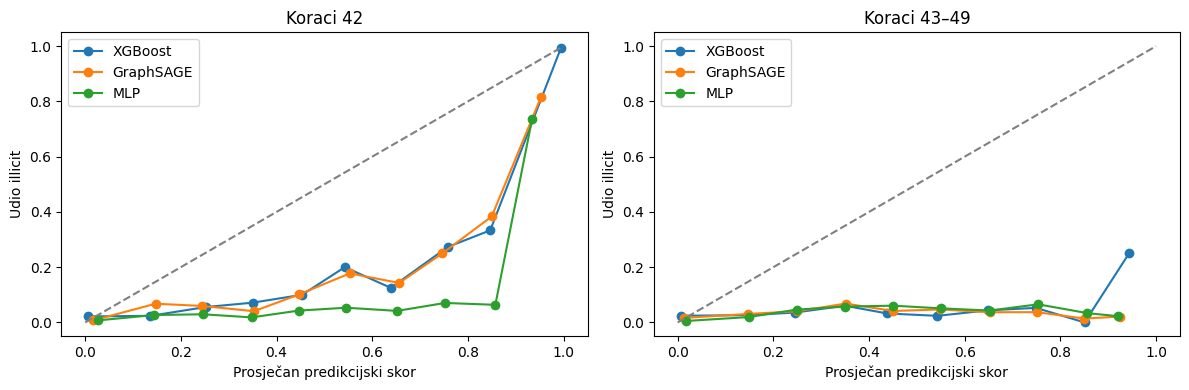

Sačuvano: outputs/phase04_diagnostics/figures/phase04_calibration_descriptive_test.png


In [ ]:
cal_rows=[]
for name,df in preds.items():
    for period,m in [('42',df.time_step==42),('43_49',df.time_step>=43)]:
        d=df.loc[m]; y=d.label.to_numpy();p=d.probability_illicit.to_numpy()
        cal_rows.append(dict(model=name,period=period,n=len(y),brier=brier_score_loss(y,p),
          mean_score=float(p.mean()),positive_rate=float(y.mean())))
save_table(pd.DataFrame(cal_rows),'brier_and_mean_scores')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,(period,choose) in zip(axes,[('42',lambda d:d.time_step==42),('43–49',lambda d:d.time_step>=43)]):
    for name,df in preds.items():
        d=df.loc[choose(df)].copy();d['bin']=pd.cut(d.probability_illicit,bins=np.linspace(0,1,11),include_lowest=True)
        grouping=d.groupby('bin',observed=True).agg(score=('probability_illicit','mean'),truth=('label','mean'),n=('label','size'))
        ax.plot(grouping.score,grouping.truth,marker='o',label=name)
    ax.plot([0,1],[0,1],'--',c='grey');ax.set(xlabel='Prosječan predikcijski skor',ylabel='Udio illicit',title=f'Koraci {period}');ax.legend()
save_fig('calibration_descriptive_test')

## 6. Drift karakteristika (PSI, KS i Wasserstein) — bez treniranja
**PSI** računamo prema kvantilnim binovima iz *trening perioda* (samo dostupne vrijednosti). KS i Wasserstein služe kao dodatni deskriptivni pokazatelji; Wasserstein u standardizovanim jedinicama. S obzirom na 182 karakteristike i broj čvorova, računanje može potrajati. Nema imputacije fitane na budućim koracima. Analizira se i `unknown` udio.

PSI je deskriptivna heuristika; ne postoje univerzalne granice koje dokazuju promjenu uzročno povezanu s padom modela.

Sačuvano: outputs/phase04_diagnostics/tables/phase04_feature_drift_full.csv


,feature,ks,psi,wasserstein_std,missing_ref,missing_new
464,Aggregate_feature_8,0.998652,8.938856,3.032258,0.000000,0.00000
499,Aggregate_feature_43,0.998093,11.822059,2.655878,0.000000,0.00000
466,Aggregate_feature_10,0.997945,8.714105,3.016817,0.000000,0.00000
463,Aggregate_feature_7,0.996496,7.776868,2.920095,0.000000,0.00000
502,Aggregate_feature_46,0.987063,11.805114,2.463515,0.000000,0.00000
500,Aggregate_feature_44,0.944792,11.806472,1.893059,0.000000,0.00000
365,Local_feature_2,0.531998,1.739458,1.009019,0.000000,0.00000
532,fees,0.531402,1.734095,1.003769,0.002943,0.00795
475,Aggregate_feature_19,0.496848,1.518872,1.124994,0.000000,0.00000
469,Aggregate_feature_13,0.490635,1.519461,1.153686,0.000000,0.00000


Sačuvano: outputs/phase04_diagnostics/tables/phase04_feature_drift_top12.csv


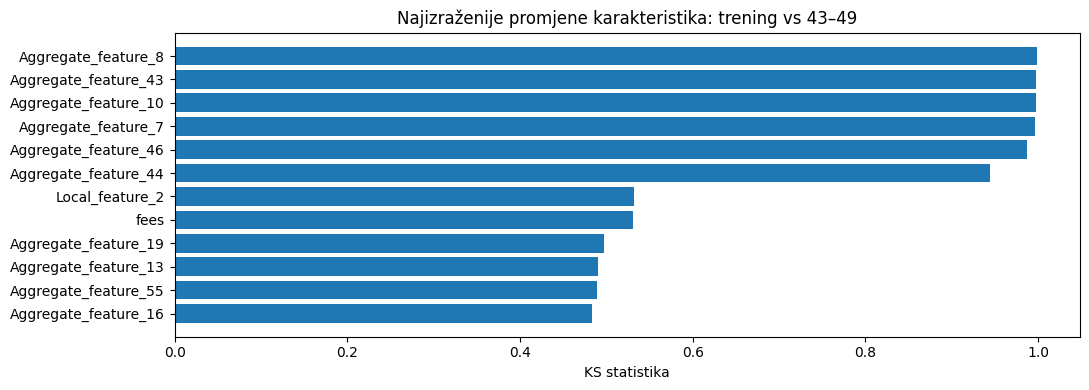

Sačuvano: outputs/phase04_diagnostics/figures/phase04_top_feature_drift_ks.png


In [ ]:
# Analiza svih čvorova i izdvojeno poznatih oznaka; očekuje se nekoliko minuta.
periods={'train_1_34':graph.times<=34,'valid_35_41':(graph.times>=35)&(graph.times<=41),
         'test_42':graph.times==42,'test_43_49':graph.times>=43}

def calc_psi(ref,new,n_bins=10):
    ref=ref[np.isfinite(ref)];new=new[np.isfinite(new)]
    if len(ref)<20 or len(new)<20:return np.nan
    cuts=np.unique(np.quantile(ref,np.linspace(0,1,n_bins+1))[1:-1])
    if len(cuts)==0:return 0.0 if np.isclose(np.nanmedian(ref),np.nanmedian(new)) else np.nan
    a=np.bincount(np.searchsorted(cuts,ref,side='right'),minlength=len(cuts)+1)/len(ref)
    b=np.bincount(np.searchsorted(cuts,new,side='right'),minlength=len(cuts)+1)/len(new)
    eps=1e-6;return float(np.sum((b-a)*np.log((b+eps)/(a+eps))))

def drift_one(ref,candidate):
    ref=ref[np.isfinite(ref)];candidate=candidate[np.isfinite(candidate)]
    if len(ref)<10 or len(candidate)<10:return (np.nan,)*4
    std=max(float(np.std(ref)),1e-12)
    return (calc_psi(ref,candidate),float(ks_2samp(ref,candidate,method='asymp').statistic),
            float(wasserstein_distance(ref/std,candidate/std)),
            float(np.median(candidate)-np.median(ref)))

rows=[]; X=graph.features
for population,selected in [('all',np.ones(graph.num_nodes,bool)),('known_only',graph.labels>=0),
                            ('illicit_only',graph.labels==1),('licit_only',graph.labels==0)]:
    base=periods['train_1_34'] & selected
    for period in ('valid_35_41','test_42','test_43_49'):
        m=periods[period]&selected
        for j,name in enumerate(graph.feature_names):
            a,b,c,d=drift_one(X[base,j],X[m,j])
            rows.append(dict(population=population,period=period,feature=name,psi=a,ks=b,
                 wasserstein_std=c,median_difference=d,n_ref=int((np.isfinite(X[base,j])).sum()),
                 n_new=int(np.isfinite(X[m,j]).sum()),missing_ref=float(np.isnan(X[base,j]).mean()),
                 missing_new=float(np.isnan(X[m,j]).mean())))
drift=pd.DataFrame(rows)
save_table(drift,'feature_drift_full')
top=(drift[(drift.population=='all')&(drift.period=='test_43_49')]
     .sort_values('ks',ascending=False).head(12))
display(top[['feature','ks','psi','wasserstein_std','missing_ref','missing_new']])
save_table(top,'feature_drift_top12')
fig,ax=plt.subplots(figsize=(11,4));d=top.sort_values('ks')
ax.barh(d.feature,d.ks);ax.set(xlabel='KS statistika',title='Najizraženije promjene karakteristika: trening vs 43–49')
save_fig('top_feature_drift_ks')

## 7. Struktura grafa i neoznačeni čvorovi
Provjeravaju se: međuvremenske veze, stepeni čvorova, raspodjela veličina slabih komponenti (neusmjereni prikaz, **samo za dijagnostiku**) i udio unknown susjeda. Ovdje se ne mijenjaju poruke GraphSAGE modela niti se `unknown` tretira kao `licit`.

In [7]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
N=graph.num_nodes
in_deg=np.bincount(dst,minlength=N);out_deg=np.bincount(src,minlength=N)
# Komponente računamo iz simetrizovane veze; slabe povezane komponente.
mat=coo_matrix((np.ones(len(src),dtype=np.uint8),(src,dst)),shape=(N,N)).tocsr()
mat=(mat+mat.T).astype(bool).astype(np.uint8)
n_comp,comp=connected_components(mat,directed=False)
comp_sizes=np.bincount(comp)
labels=graph.labels
unknown_neighbor_count=np.bincount(src,weights=(labels[dst]==-1),minlength=N)+np.bincount(dst,weights=(labels[src]==-1),minlength=N)
undeg=in_deg+out_deg
node_stats=pd.DataFrame({'txId':graph.tx_ids,'time_step':graph.times,'label':labels,
 'degree':undeg,'component_id':comp,'component_size':comp_sizes[comp],
 'unknown_neighbor_fraction':np.divide(unknown_neighbor_count,undeg,out=np.zeros(N,float),where=undeg>0)})
node_summary=node_stats.groupby(['time_step','label'],as_index=False).agg(n=('txId','size'),
    mean_degree=('degree','mean'),median_degree=('degree','median'),
    mean_unknown_neighbor_fraction=('unknown_neighbor_fraction','mean'))
save_table(node_summary,'graph_structure_by_time_and_label')
save_table(pd.DataFrame({'component_size':comp_sizes}).groupby('component_size').size().rename('count').reset_index(),
           'weak_component_size_distribution')
print('Broj slabih komponenti:',n_comp,'max veličina:',max(comp_sizes),'medijan:',np.median(comp_sizes))
print('Sve veze u istom koraku:',bool(np.all(graph.times[src]==graph.times[dst])))
print('Prosječan udio unknown susjeda:',float(node_stats.unknown_neighbor_fraction.mean()))

Sačuvano: outputs/phase04_diagnostics/tables/phase04_graph_structure_by_time_and_label.csv
Sačuvano: outputs/phase04_diagnostics/tables/phase04_weak_component_size_distribution.csv
Broj slabih komponenti: 49 max veličina: 7880 medijan: 4291.0
Sve veze u istom koraku: True
Prosječan udio unknown susjeda: 0.6927427549483102


## 8. Dva ili tri visokorizična podgrafa (eksploratorno)
Biraju se čvorovi s velikim skorom iz **originalnih sačuvanih testnih predikcija**, uz nastojanje da se razlikuju njihove lokalne komponente. Vizualizujemo do dva koraka susjedstva sa najviše `MAX_NODES` čvorova. Graf se prikazuje neusmjereno samo radi čitljivosti, a **izvorni smjer veza** zadržava se u CSV listi rubova.

Ovi podgrafovi **nisu potvrđene kriminalne mreže**; `unknown` čvorovi ostaju neoznačeni. Prikaz smije biti ograničen na 2 hops i ne dokazuje da su čvorovi u istom kriminalnom lancu.

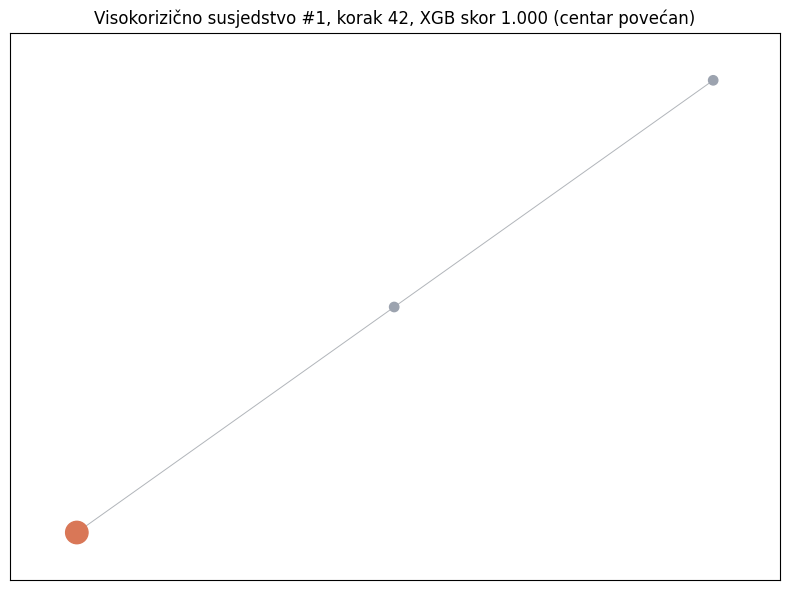

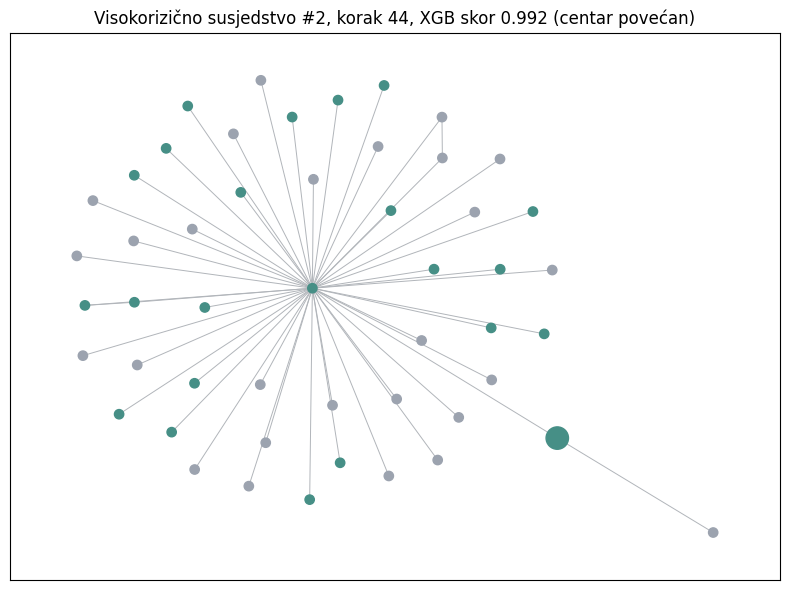

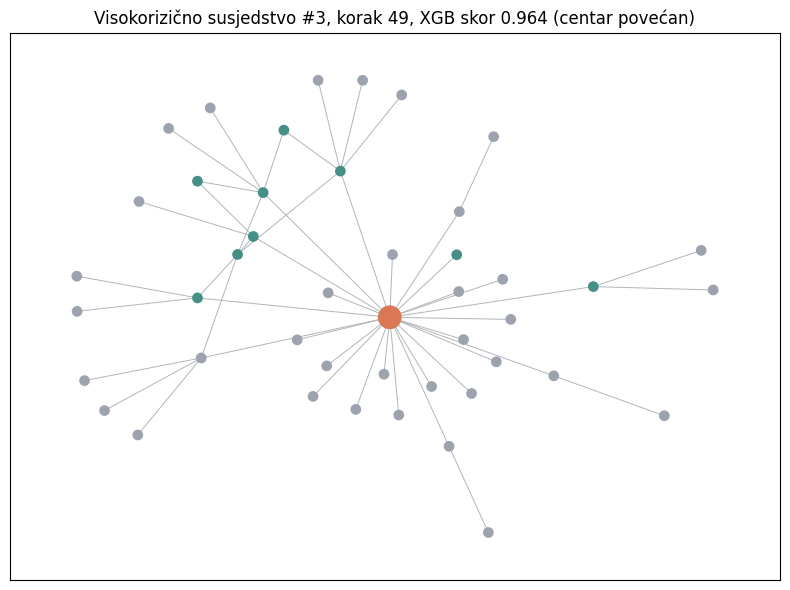

Sačuvano: outputs/phase04_diagnostics/tables/phase04_subgraphs_summary.csv


,example,center_txId,time_step,xgb_score,n_nodes,n_edges,known_illicit,known_licit,unknown,component_size
0,1,71988716,42,0.999887,3,2,1,0,2,7140
1,2,105809538,44,0.991593,50,51,0,23,27,4975
2,3,190135471,49,0.964014,45,50,1,9,35,2454


In [ ]:
# Prostor za visokorizične čvorove, biramo primjere iz različitih komponenti ako ih ima.
MAX_NODES=75;N_EXAMPLES=3;HOPS=2
xpred=preds['XGBoost'].copy().sort_values('probability_illicit',ascending=False)
id_to_idx=pd.Series(np.arange(N,dtype=int),index=graph.tx_ids)
chosen=[];used_components=set();used_nodes=set()
for _,r in xpred.iterrows():
    i=int(id_to_idx.loc[r.txId]);ci=int(comp[i])
    if ci in used_components or i in used_nodes:continue
    chosen.append((i,float(r.probability_illicit)));used_components.add(ci)
    if len(chosen)==N_EXAMPLES:break
# Ako nema dovoljno razlicitih komponenti, koristi drugi seed iz iste komponente.
if len(chosen)<N_EXAMPLES:
    for _,r in xpred.iterrows():
        i=int(id_to_idx.loc[r.txId]);
        if i in {v[0] for v in chosen}:continue
        chosen.append((i,float(r.probability_illicit)))
        if len(chosen)==N_EXAMPLES:break

sub_summaries=[]
for order,(seed,score) in enumerate(chosen,1):
    visited={seed};front={seed}
    for hop in range(HOPS):
        nxt=set()
        for ix in front:
            nxt.update(mat[ix].indices.tolist())
        # Deterministic cap based on graph distance then txId; include center.
        nxt-=visited
        room=max(0,MAX_NODES-len(visited))
        nxt=set(sorted(nxt,key=lambda ix:int(graph.tx_ids[ix]))[:room])
        visited.update(nxt);front=nxt
        if not nxt or len(visited)>=MAX_NODES:break
    ids=sorted(visited);local=set(ids)
    edge_mask=np.isin(src,ids)&np.isin(dst,ids)
    ei=np.flatnonzero(edge_mask)
    nodes_df=pd.DataFrame({'row_index':ids,'txId':graph.tx_ids[ids],
        'time_step':graph.times[ids],'label':graph.labels[ids],
        'degree_total':undeg[ids]})
    for name,df in preds.items():
        mapper=df.set_index('txId').probability_illicit
        nodes_df[f'score_{name}']=nodes_df.txId.map(mapper)
    ed_df=pd.DataFrame({'source_txId':graph.tx_ids[src[ei]],'target_txId':graph.tx_ids[dst[ei]]})
    nodes_df.to_csv(SUBGRAPHS/f'phase04_risk_subgraph_{order}_nodes.csv',index=False)
    ed_df.to_csv(SUBGRAPHS/f'phase04_risk_subgraph_{order}_directed_edges.csv',index=False)
    GG=nx.Graph();GG.add_nodes_from(ids)
    GG.add_edges_from([(int(a),int(b)) for a,b in zip(src[ei],dst[ei])])
    pos=nx.spring_layout(GG,seed=SEED)
    colors=[{1:'#d97757',0:'#468f86',-1:'#9ca3af'}[int(labels[ix])] for ix in GG.nodes()]
    sizes=[260 if ix==seed else 45 for ix in GG.nodes()]
    plt.figure(figsize=(8,6));nx.draw_networkx(GG,pos,node_color=colors,node_size=sizes,
      with_labels=False,edge_color='#b1b5ba',width=.7)
    plt.title(f'Visokorizično susjedstvo #{order}, korak {graph.times[seed]}, XGB skor {score:.3f} (centar povećan)')
    fig_path=SUBGRAPHS/f'phase04_risk_subgraph_{order}.png'
    plt.tight_layout();plt.savefig(fig_path,dpi=175,bbox_inches='tight');plt.show()
    sub_summaries.append(dict(example=order,center_txId=int(graph.tx_ids[seed]),time_step=int(graph.times[seed]),
        xgb_score=score,n_nodes=len(ids),n_edges=len(ei),known_illicit=int(np.sum(labels[ids]==1)),
        known_licit=int(np.sum(labels[ids]==0)),unknown=int(np.sum(labels[ids]==-1)),
        component_size=int(comp_sizes[comp[seed]])))
sub_summaries=pd.DataFrame(sub_summaries);save_table(sub_summaries,'subgraphs_summary');display(sub_summaries)

## 9. Hronološke validacijske podjele (bez pretrage hiperparametara)
Predložene podjele su **unutar koraka 1–41** i nisu novi test: (1–20 → 21–27), (1–27 → 28–34), (1–34 → 35–41). Provjeravamo da svaka sadrži obje označene klase. U narednoj ćeliji se prvo dobije raspodjela oznaka; treniranje se može uključiti nakon pregleda.

**Važno:** tri podjele ne koriste isti broj trening primjera. Rezultati služe za dijagnostiku vremenske nestabilnosti početne konfiguracije, ne kao direktna procjena performansi na potpuno neviđenom testu.

In [8]:
ROLLING_FOLDS=[('fold_A',20,27),('fold_B',27,34),('fold_C',34,41)]
fold_rows=[]
for name,tend,vend in ROLLING_FOLDS:
    tr=(graph.times<=tend)&(labels>=0)
    va=(graph.times>tend)&(graph.times<=vend)&(labels>=0)
    for splitname,mask in [('train',tr),('validation',va)]:
        fold_rows.append(dict(fold=name,split=splitname,train_end=tend,valid_end=vend,
            n=int(mask.sum()),illicit=int((labels[mask]==1).sum()),licit=int((labels[mask]==0).sum()),
            positive_rate=float((labels[mask]==1).mean()) if mask.any() else np.nan))
        assert (labels[mask]==1).any() and (labels[mask]==0).any(),f'{name}/{splitname}: nema obje klase'
folds_summary=pd.DataFrame(fold_rows);save_table(folds_summary,'rolling_folds_class_counts');display(folds_summary)

Sačuvano: outputs/phase04_diagnostics/tables/phase04_rolling_folds_class_counts.csv


,fold,split,train_end,valid_end,n,illicit,licit,positive_rate
0,fold_A,train,20,27,18889,1771,17118,0.093758
1,fold_A,validation,20,27,6034,686,5348,0.113689
2,fold_B,train,27,34,24923,2457,22466,0.098584
3,fold_B,validation,27,34,4971,1005,3966,0.202173
4,fold_C,train,34,41,29894,3462,26432,0.115809
5,fold_C,validation,34,41,7829,675,7154,0.086218


## 10. Opcionalno: ponovljeno treniranje početnih modela na tri podjele
**Ovdje se prvi put ponovo trenira**. Sve postavke ostaju jednake verziji 3: XGBoost (350 stabala, max_depth 5, lr 0.05), MLP (128/64, lr 0.001, dropout 0.3), GraphSAGE (2 sloja, 64, lr 0.001, dropout 0.3). Rani prekid koristi validacijski AP. Izlazi su zasebni `phase04_fold_*` CSV i JSON fajlovi. Ne koriste se koraci 42–49 ni pri fitovanju predobrade ni pri računaju novih rezultata.

**Oprez:** GraphSAGE je najzahtjevniji i može zauzeti znatnu GPU memoriju. Za pokretanje u Colabu odabrati GPU; prvo uključiti XGBoost pa MLP, a zatim GraphSAGE. Ako je GPU spor ili memorija nedovoljna, ostaviti GraphSAGE isključen i poslati ostale rezultate.

In [9]:
RUN_ROLLING_XGBOOST = True
RUN_ROLLING_MLP = True
RUN_ROLLING_GRAPHSAGE = True
# Promijeni pojedinačni prekidač na True kada želiš pokrenuti opcionalni trening.
# Nema testnog skupa u ovom bloku.

In [10]:
def fold_masks(train_end,valid_end):
    tr=(graph.times<=train_end)&(graph.labels>=0)
    va=(graph.times>train_end)&(graph.times<=valid_end)&(graph.labels>=0)
    return tr,va

def fold_preprocess(tr,tend,scale=False):
    imputer=SimpleImputer(strategy='median',keep_empty_features=True)
    imputer.fit(graph.features[graph.times<=tend])
    if scale:
        scaler=StandardScaler().fit(imputer.transform(graph.features[graph.times<=tend]))
        trans=lambda mask:scaler.transform(imputer.transform(graph.features[mask])).astype('float32')
    else:trans=lambda mask:imputer.transform(graph.features[mask]).astype('float32')
    return trans

def fold_result(modelname,foldname,tend,vend,valid_mask,probs,history=None):
    from fingraph.metrics import choose_f1_threshold,evaluate
    threshold=choose_f1_threshold(labels[valid_mask],probs)
    metrics=evaluate(labels[valid_mask],probs,threshold)
    dest=RUNS/f'phase04_{foldname}_{modelname.lower()}';dest.mkdir(parents=True,exist_ok=True)
    pd.DataFrame({'txId':graph.tx_ids[valid_mask],'time_step':graph.times[valid_mask],
         'label':labels[valid_mask],'probability_illicit':probs}).to_csv(dest/'phase04_validation_predictions.csv',index=False)
    info={'phase':'04 diagnostics','fold':foldname,'model':modelname,'train_end':tend,
         'valid_end':vend,'seed':SEED,'metrics':metrics,'validation_only':True}
    (dest/'phase04_validation_metrics.json').write_text(json.dumps(info,indent=2,default=str),encoding='utf8')
    if history is not None:pd.DataFrame(history).to_csv(dest/'phase04_training_history.csv',index=False)
    return dict(fold=foldname,model=modelname,**{k:v for k,v in metrics.items() if isinstance(v,(float,int))})

rolling_results=[]
if RUN_ROLLING_XGBOOST:
    from xgboost import XGBClassifier
    for foldname,tend,vend in ROLLING_FOLDS:
        tr,va=fold_masks(tend,vend);transform=fold_preprocess(tr,tend,scale=False)
        y=labels[tr]
        model=XGBClassifier(n_estimators=350,max_depth=5,learning_rate=.05,
          subsample=.85,colsample_bytree=.85,tree_method='hist',objective='binary:logistic',
          eval_metric='logloss',scale_pos_weight=(y==0).sum()/(y==1).sum(),random_state=SEED,n_jobs=2)
        model.fit(transform(tr),y)
        p=model.predict_proba(transform(va))[:,1]
        rolling_results.append(fold_result('XGBoost',foldname,tend,vend,va,p))
    print('XGBoost rolling završeno')

XGBoost rolling završeno


In [11]:
if RUN_ROLLING_MLP:
    import torch
    from torch import nn
    torch.manual_seed(SEED); np.random.seed(SEED)
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    for foldname,tend,vend in ROLLING_FOLDS:
        torch.manual_seed(SEED)
        tr,va=fold_masks(tend,vend);transform=fold_preprocess(tr,tend,scale=True)
        xtr=torch.as_tensor(transform(tr),device=device);ytr=torch.as_tensor(labels[tr],dtype=torch.long,device=device)
        xva=torch.as_tensor(transform(va),device=device)
        model=nn.Sequential(nn.Linear(xtr.shape[1],128),nn.ReLU(),nn.Dropout(.3),
            nn.Linear(128,64),nn.ReLU(),nn.Dropout(.3),nn.Linear(64,2)).to(device)
        opt=torch.optim.Adam(model.parameters(),lr=.001,weight_decay=1e-4)
        weight=torch.tensor([1.,float((labels[tr]==0).sum()/(labels[tr]==1).sum())],device=device)
        best=-1.;best_state=None;best_ep=0;bad=0;history=[]
        for ep in range(1,151):
            model.train();opt.zero_grad();logits=model(xtr)
            loss=nn.functional.cross_entropy(logits,ytr,weight=weight);loss.backward();opt.step()
            model.eval()
            with torch.no_grad():vp=torch.softmax(model(xva),dim=1)[:,1].cpu().numpy()
            ap=float(average_precision_score(labels[va],vp));history.append(dict(epoch=ep,train_loss=float(loss.item()),val_pr_auc=ap))
            if ap>best+1e-5:best=ap;best_state=copy.deepcopy(model.state_dict());best_ep=ep;bad=0
            else:bad+=1
            if bad>=20:break
        model.load_state_dict(best_state);model.eval()
        with torch.no_grad():vp=torch.softmax(model(xva),dim=1)[:,1].cpu().numpy()
        rr=fold_result('MLP',foldname,tend,vend,va,vp,history);rr['best_epoch']=best_ep;rolling_results.append(rr)
        print(foldname,'MLP',best_ep,round(best,4))
    print('MLP rolling završeno')

fold_A MLP 7 0.6648
fold_B MLP 6 0.6938
fold_C MLP 28 0.7294
MLP rolling završeno


In [13]:
!pip install torch-geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 10.2 MB/s  0:00:00


In [14]:
if RUN_ROLLING_GRAPHSAGE:
    import torch
    import torch.nn.functional as F
    from torch_geometric.nn import SAGEConv
    from torch_geometric.utils import to_undirected
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    class TwoLayerSAGE(torch.nn.Module):
        def __init__(self,dim):
            super().__init__();self.c1=SAGEConv(dim,64);self.c2=SAGEConv(64,2)
        def forward(self,x,edge):return self.c2(F.dropout(F.relu(self.c1(x,edge)),p=.3,training=self.training),edge)
    for foldname,tend,vend in ROLLING_FOLDS:
        torch.manual_seed(SEED);np.random.seed(SEED)
        tr,va=fold_masks(tend,vend);transform=fold_preprocess(tr,tend,scale=True)
        # x sadrži samo već posmatrane čvorove do valid_end. Indeksi se remapiraju.
        observed=graph.times<=vend
        old_rows=np.flatnonzero(observed);remap=np.full(N,-1,dtype=np.int64);remap[old_rows]=np.arange(len(old_rows))
        x=torch.as_tensor(transform(observed),device=device)
        e=graph.edge_index
        e_train=e[:,(graph.times[e[0]]<=tend)&(graph.times[e[1]]<=tend)]
        e_valid=e[:,(graph.times[e[0]]<=vend)&(graph.times[e[1]]<=vend)]
        et=torch.as_tensor(remap[e_train],device=device,dtype=torch.long)
        ev=torch.as_tensor(remap[e_valid],device=device,dtype=torch.long)
        et=to_undirected(et,num_nodes=len(old_rows));ev=to_undirected(ev,num_nodes=len(old_rows))
        yy=torch.as_tensor(labels[observed],device=device,dtype=torch.long)
        train_nodes=torch.as_tensor(remap[np.flatnonzero(tr)],device=device)
        valid_nodes=torch.as_tensor(remap[np.flatnonzero(va)],device=device)
        model=TwoLayerSAGE(x.shape[1]).to(device)
        opt=torch.optim.Adam(model.parameters(),lr=.001,weight_decay=1e-4)
        class_weight=torch.tensor([1.,float((labels[tr]==0).sum()/(labels[tr]==1).sum())],device=device)
        best=-1.;best_state=None;best_ep=0;bad=0;history=[]
        for ep in range(1,61):
            model.train();opt.zero_grad();z=model(x,et)
            loss=F.cross_entropy(z[train_nodes],yy[train_nodes],weight=class_weight)
            loss.backward();opt.step()
            model.eval()
            with torch.no_grad():p=torch.softmax(model(x,ev)[valid_nodes],dim=1)[:,1].cpu().numpy()
            ap=float(average_precision_score(labels[va],p))
            history.append(dict(epoch=ep,train_loss=float(loss.item()),val_pr_auc=ap))
            if ap>best+1e-5:best=ap;best_state=copy.deepcopy(model.state_dict());best_ep=ep;bad=0
            else:bad+=1
            if bad>=10:break
        model.load_state_dict(best_state);model.eval()
        with torch.no_grad():p=torch.softmax(model(x,ev)[valid_nodes],dim=1)[:,1].cpu().numpy()
        rr=fold_result('GraphSAGE',foldname,tend,vend,va,p,history);rr['best_epoch']=best_ep;rolling_results.append(rr)
        print(foldname,'GraphSAGE',best_ep,round(best,4))
    print('GraphSAGE rolling završeno')
if rolling_results:
    results=pd.DataFrame(rolling_results);save_table(results,'rolling_baselines_summary');display(results)
else:
    print('Rolling treniranje nije uključeno; promijeni prekidače na True za novi eksperimentski izlaz.')

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


fold_A GraphSAGE 25 0.6321
fold_B GraphSAGE 60 0.8315
fold_C GraphSAGE 58 0.5384
GraphSAGE rolling završeno
Sačuvano: outputs/phase04_diagnostics/tables/phase04_rolling_baselines_summary.csv


,fold,model,n,positives,threshold,pr_auc,roc_auc,precision,recall,f1,precision_at_100_or_less,recall_at_100_or_less,best_epoch
0,fold_A,XGBoost,6034,686,0.92,0.861703,0.920720,0.973635,0.753644,0.849630,1.00,0.145773,NaN
1,fold_B,XGBoost,4971,1005,0.35,0.980591,0.994999,0.925676,0.954229,0.939735,0.99,0.098507,NaN
2,fold_C,XGBoost,7829,675,0.77,0.934104,0.978634,0.976974,0.880000,0.925955,1.00,0.148148,NaN
3,fold_A,MLP,6034,686,0.58,0.664807,0.883928,0.805031,0.559767,0.660361,0.89,0.129738,7.0
4,fold_B,MLP,4971,1005,0.56,0.693845,0.831953,0.770982,0.539303,0.634660,0.99,0.098507,6.0
5,fold_C,MLP,7829,675,0.91,0.729359,0.924894,0.812253,0.608889,0.696020,0.94,0.139259,28.0
6,fold_A,GraphSAGE,6034,686,0.95,0.632075,0.877876,0.671429,0.548105,0.603531,0.94,0.137026,25.0
7,fold_B,GraphSAGE,4971,1005,0.83,0.831528,0.947356,0.671839,0.861692,0.755013,1.00,0.099502,60.0
8,fold_C,GraphSAGE,7829,675,0.87,0.538424,0.884630,0.550889,0.505185,0.527048,0.87,0.128889,58.0


## 11. Završni manifest i šta poslati na analizu
Pokreni ovu ćeliju na kraju. Manifest sadrži listu generisanih fajlova. Pošalji `.zip` s `outputs/phase04_diagnostics/` i, ako bude potrebno, zasebno rezultate rolling treniranja. **Ne treba slati originalni Elliptic++ sirovi CSV**, niti checkpoint modele za početnu interpretaciju. Nemoj uključivati identifikatore stvarnih korisnika izvan javnog dataseta.

In [15]:
import zipfile, datetime
files=sorted(p for p in OUT.rglob('*') if p.is_file() and not p.name.endswith('.zip'))
manifest={'phase':'04-diagnostics','project':str(PROJECT_DIR),'generated_at_utc':datetime.datetime.now(datetime.timezone.utc).isoformat(),
 'models':['XGBoost','GraphSAGE','MLP'],'original_test_is_exploratory':True,
 'rolling_folds':ROLLING_FOLDS,'rolling_enabled':{'xgboost':RUN_ROLLING_XGBOOST,'mlp':RUN_ROLLING_MLP,
 'graphsage':RUN_ROLLING_GRAPHSAGE},'files':[str(p.relative_to(OUT)) for p in files]}
manifest_path=dump_json(manifest,'manifest')
zip_path=OUT.parent/'phase04_diagnostics_results.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob('*')):
        if p.is_file():z.write(p,arcname=str(p.relative_to(OUT.parent)))
print('Rezultati:',len(files),'datoteka');print('ZIP:',zip_path)

Rezultati: 59 datoteka
ZIP: outputs/phase04_diagnostics_results.zip
